In [3]:
import os

print(os.path.exists("../../data/clean/prices_clean.csv"))

False


In [4]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFolders/files here:")
print(os.listdir())

Current folder:
c:\Projects\Financial-markets-dashboard\notebooks

Folders/files here:
['01_download_data.ipynb', '02_cleaning.ipynb', '03_load_mysql.ipynb', '04_python_analysis.ipynb']


In [5]:
import os

for root, dirs, files in os.walk("../../"):
    if "prices_clean.csv" in files:
        print("FOUND:")
        print(os.path.join(root, "prices_clean.csv"))

FOUND:
../../Financial-markets-dashboard\data\clean\prices_clean.csv


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/clean/prices_clean.csv")

df["date"] = pd.to_datetime(df["date"])

df = df.sort_values(
    ["ticker", "date"]
).reset_index(drop=True)

print("Rows:", len(df))
print("Columns:", list(df.columns))

df.head()

Rows: 10024
Columns: ['date', 'ticker', 'open', 'high', 'low', 'close', 'volume']


,date,ticker,open,high,low,close,volume
0,2021-10-01 04:00:00,AAPL,138.405130,139.400012,135.683851,139.136658,94639600
1,2021-10-04 04:00:00,AAPL,138.268618,138.707547,134.864582,135.713150,98322000
2,2021-10-05 04:00:00,AAPL,136.054532,138.736802,135.927729,137.634628,80861100
3,2021-10-06 04:00:00,AAPL,136.035013,138.649001,134.962099,138.502701,83221100
4,2021-10-07 04:00:00,AAPL,139.536609,140.668044,139.204987,139.760941,61732700


In [7]:
df["daily_return"] = (
    df.groupby("ticker")["close"]
      .pct_change()
)

df[["date", "ticker", "close", "daily_return"]].head(15)

,date,ticker,close,daily_return
0,2021-10-01 04:00:00,AAPL,139.136658,NaN
1,2021-10-04 04:00:00,AAPL,135.713150,-0.024605
2,2021-10-05 04:00:00,AAPL,137.634628,0.014158
3,2021-10-06 04:00:00,AAPL,138.502701,0.006307
4,2021-10-07 04:00:00,AAPL,139.760941,0.009085
5,2021-10-08 04:00:00,AAPL,139.380539,-0.002722
6,2021-10-11 04:00:00,AAPL,139.292755,-0.000630
7,2021-10-12 04:00:00,AAPL,138.024780,-0.009103
8,2021-10-13 04:00:00,AAPL,137.439560,-0.004240
9,2021-10-14 04:00:00,AAPL,140.219360,0.020226


In [8]:
df["daily_return"].describe()

count    10016.000000
mean         0.000493
std          0.013444
min         -0.102742
25%         -0.005662
50%          0.000572
75%          0.006769
max          0.155067
Name: daily_return, dtype: float64

In [9]:
df["cumulative_return"] = (
    df.groupby("ticker")["daily_return"]
      .transform(lambda x: (1 + x).cumprod() - 1)
)

df[
    ["date", "ticker", "daily_return", "cumulative_return"]
].tail(15)

,date,ticker,daily_return,cumulative_return
10009,2026-09-09 04:00:00,TLT,-0.005718,-0.330096
10010,2026-09-10 04:00:00,TLT,-0.011624,-0.337883
10011,2026-09-11 04:00:00,TLT,0.001114,-0.337145
10012,2026-09-14 04:00:00,TLT,0.000742,-0.336653
10013,2026-09-15 04:00:00,TLT,-0.002718,-0.338456
10014,2026-09-16 04:00:00,TLT,0.002106,-0.337063
10015,2026-09-17 04:00:00,TLT,0.011128,-0.329686
10016,2026-09-18 04:00:00,TLT,-0.006481,-0.334030
10017,2026-09-21 04:00:00,TLT,0.006769,-0.329522
10018,2026-09-22 04:00:00,TLT,-0.000611,-0.329932


In [10]:
performance = (
    df.groupby("ticker")
      .agg(
          cumulative_return=("cumulative_return", "last"),
          average_daily_return=("daily_return", "mean"),
          daily_volatility=("daily_return", "std")
      )
)

performance

,cumulative_return,average_daily_return,daily_volatility
ticker,,,
AAPL,1.367457,0.000844,0.017685
AGG,-0.033071,-0.000019,0.003870
GLD,1.326326,0.000746,0.011915
JPM,1.271412,0.000773,0.015348
MSFT,0.834373,0.000641,0.017769
QQQ,1.110940,0.000702,0.014492
SPY,0.881590,0.000563,0.010819
TLT,-0.358784,-0.000306,0.009888


In [11]:
annualized_volatility = (
    df.groupby("ticker")["daily_return"]
      .std()
      * np.sqrt(252)
)

annualized_volatility = annualized_volatility.sort_values(
    ascending=False
)

annualized_volatility

ticker
MSFT    0.282067
AAPL    0.280733
JPM     0.243635
QQQ     0.230053
GLD     0.189141
SPY     0.171751
TLT     0.156967
AGG     0.061428
Name: daily_return, dtype: float64

In [12]:
performance["annualized_volatility"] = annualized_volatility

performance = performance.sort_values(
    "cumulative_return",
    ascending=False
)

performance

,cumulative_return,average_daily_return,daily_volatility,annualized_volatility
ticker,,,,
AAPL,1.367457,0.000844,0.017685,0.280733
GLD,1.326326,0.000746,0.011915,0.189141
JPM,1.271412,0.000773,0.015348,0.243635
QQQ,1.110940,0.000702,0.014492,0.230053
SPY,0.881590,0.000563,0.010819,0.171751
MSFT,0.834373,0.000641,0.017769,0.282067
AGG,-0.033071,-0.000019,0.003870,0.061428
TLT,-0.358784,-0.000306,0.009888,0.156967


In [13]:
performance_display = performance.copy()

performance_display["cumulative_return"] *= 100
performance_display["average_daily_return"] *= 100
performance_display["annualized_volatility"] *= 100

performance_display.round(2)

,cumulative_return,average_daily_return,daily_volatility,annualized_volatility
ticker,,,,
AAPL,136.75,0.08,0.02,28.07
GLD,132.63,0.07,0.01,18.91
JPM,127.14,0.08,0.02,24.36
QQQ,111.09,0.07,0.01,23.01
SPY,88.16,0.06,0.01,17.18
MSFT,83.44,0.06,0.02,28.21
AGG,-3.31,-0.00,0.00,6.14
TLT,-35.88,-0.03,0.01,15.70


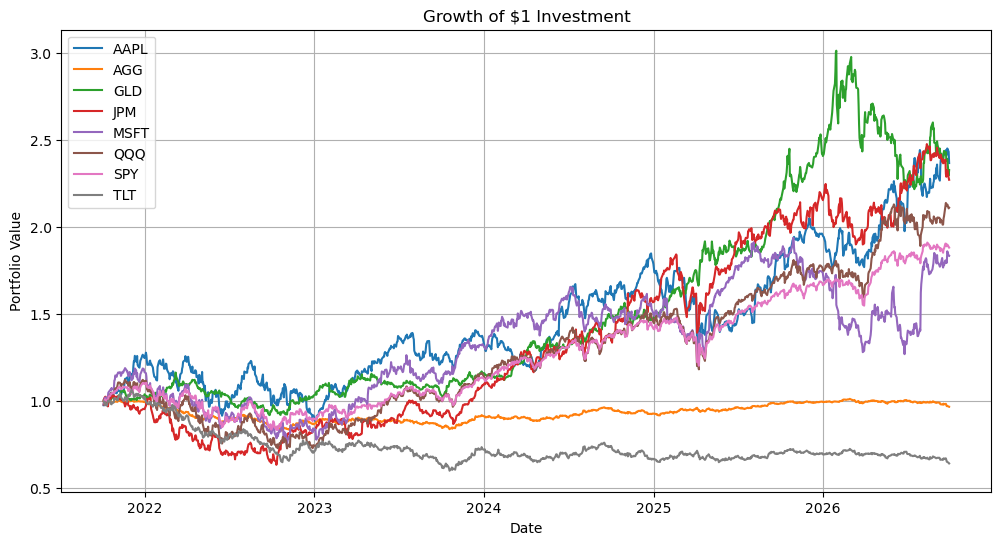

In [14]:
plt.figure(figsize=(12, 6))

for ticker in df["ticker"].unique():
    asset = df[df["ticker"] == ticker]

    plt.plot(
        asset["date"],
        1 + asset["cumulative_return"],
        label=ticker
    )

plt.title("Growth of $1 Investment")
plt.xlabel("Date")
plt.ylabel("Portfolio Value")
plt.legend()
plt.grid(True)

plt.show()

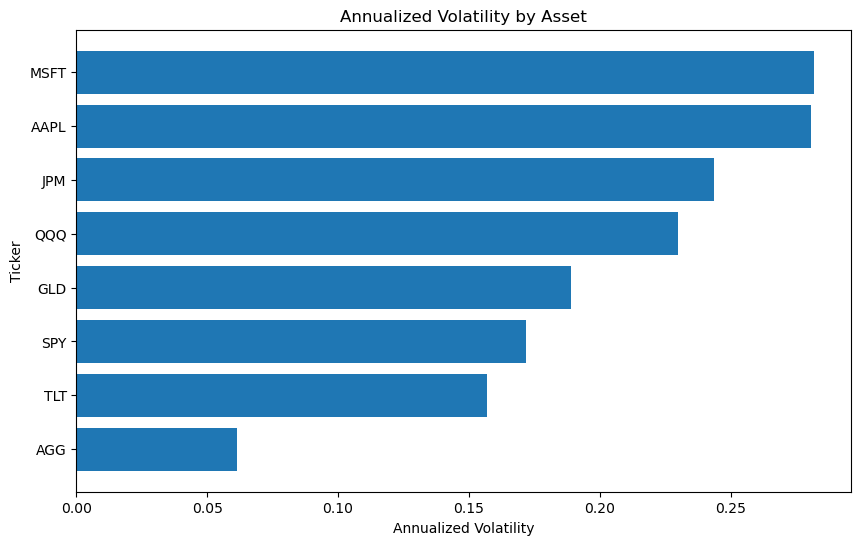

In [15]:
volatility_plot = annualized_volatility.sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    volatility_plot.index,
    volatility_plot.values
)

plt.title("Annualized Volatility by Asset")
plt.xlabel("Annualized Volatility")
plt.ylabel("Ticker")

plt.show()

In [16]:
volatility_percent = (
    annualized_volatility * 100
).sort_values()

volatility_percent

ticker
AGG      6.142850
TLT     15.696659
SPY     17.175135
GLD     18.914080
QQQ     23.005329
JPM     24.363468
AAPL    28.073306
MSFT    28.206721
Name: daily_return, dtype: float64

In [17]:
returns = df.pivot(
    index="date",
    columns="ticker",
    values="daily_return"
)

returns.head()

ticker,AAPL,AGG,GLD,JPM,MSFT,QQQ,SPY,TLT
date,,,,,,,,
2021-10-01 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-10-04 04:00:00,-0.024605,-0.000695,0.004678,-0.001077,-0.020720,-0.020990,-0.012896,-0.002545
2021-10-05 04:00:00,0.014158,-0.002350,-0.004657,0.016330,0.019957,0.013499,0.010405,-0.009657
2021-10-06 04:00:00,0.006307,0.000436,0.002673,0.002135,0.015064,0.006408,0.004156,0.005641
2021-10-07 04:00:00,0.009085,-0.002789,-0.005272,0.006330,0.005936,0.009175,0.008646,-0.010458


In [18]:
correlation = returns.corr()

correlation.round(2)

ticker,AAPL,AGG,GLD,JPM,MSFT,QQQ,SPY,TLT
ticker,,,,,,,,
AAPL,1.00,0.16,0.05,0.36,0.53,0.70,0.72,0.07
AGG,0.16,1.00,0.30,0.00,0.13,0.21,0.22,0.92
GLD,0.05,0.30,1.00,0.05,0.07,0.15,0.15,0.21
JPM,0.36,0.00,0.05,1.00,0.30,0.48,0.62,-0.07
MSFT,0.53,0.13,0.07,0.30,1.00,0.72,0.69,0.03
QQQ,0.70,0.21,0.15,0.48,0.72,1.00,0.95,0.08
SPY,0.72,0.22,0.15,0.62,0.69,0.95,1.00,0.09
TLT,0.07,0.92,0.21,-0.07,0.03,0.08,0.09,1.00


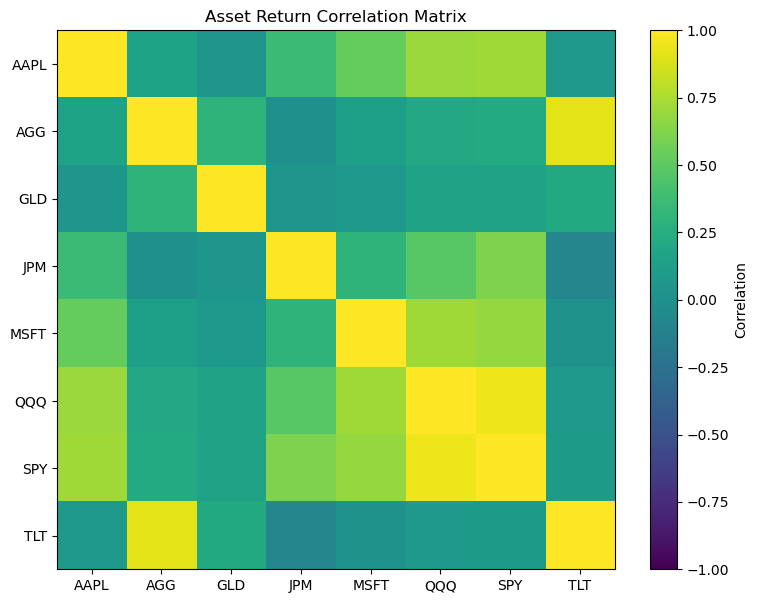

In [19]:
fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(
    correlation,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(correlation.columns)))
ax.set_yticks(range(len(correlation.index)))

ax.set_xticklabels(correlation.columns)
ax.set_yticklabels(correlation.index)

plt.colorbar(
    im,
    ax=ax,
    label="Correlation"
)

plt.title("Asset Return Correlation Matrix")

plt.show()

In [20]:
corr_pairs = correlation.where(
    np.triu(
        np.ones(correlation.shape),
        k=1
    ).astype(bool)
)

corr_pairs = corr_pairs.stack().sort_values(
    ascending=False
)

corr_pairs.head(10)

ticker  ticker
QQQ     SPY       0.950307
AGG     TLT       0.916840
MSFT    QQQ       0.716378
AAPL    SPY       0.716344
        QQQ       0.700787
MSFT    SPY       0.687183
JPM     SPY       0.615897
AAPL    MSFT      0.528392
JPM     QQQ       0.479302
AAPL    JPM       0.360016
dtype: float64

In [21]:
import os

os.makedirs("../data/clean", exist_ok=True)

performance_display.round(2).to_csv(
    "../data/clean/performance_summary.csv"
)

correlation.round(4).to_csv(
    "../data/clean/correlation_matrix.csv"
)

print("Analysis results saved successfully!")

Analysis results saved successfully!


In [3]:
import pandas as pd
import numpy as np

# Load the cleaned price data
prices_df = pd.read_csv(
    r"C:\Projects\Financial-markets-dashboard\data\clean\prices_clean.csv"
)

# Check the available columns
print(prices_df.columns.tolist())

prices_df.head()

['date', 'ticker', 'open', 'high', 'low', 'close', 'volume']


,date,ticker,open,high,low,close,volume
0,2021-10-01 04:00:00,AAPL,138.405160,139.400043,135.683881,139.136688,94639600
1,2021-10-04 04:00:00,AAPL,138.268556,138.707484,134.864521,135.713089,98322000
2,2021-10-05 04:00:00,AAPL,136.054517,138.736787,135.927714,137.634613,80861100
3,2021-10-06 04:00:00,AAPL,136.035028,138.649016,134.962114,138.502716,83221100
4,2021-10-07 04:00:00,AAPL,139.536579,140.668013,139.204956,139.760910,61732700


In [4]:
# Convert the date column to datetime
prices_df["date"] = pd.to_datetime(prices_df["date"])

# Sort the data by ticker and date
prices_df = prices_df.sort_values(["ticker", "date"])

# Calculate daily percentage returns for each asset
prices_df["daily_return"] = (
    prices_df.groupby("ticker")["close"].pct_change()
)

# Create a table with dates as rows and tickers as columns
returns_df = prices_df.pivot(
    index="date",
    columns="ticker",
    values="daily_return"
)

# Calculate correlations between the daily returns
correlation_matrix = returns_df.corr()

# Display the result
correlation_matrix.round(2)

ticker,AAPL,AGG,GLD,JPM,MSFT,QQQ,SPY,TLT
ticker,,,,,,,,
AAPL,1.00,0.16,0.05,0.36,0.53,0.70,0.72,0.07
AGG,0.16,1.00,0.30,0.00,0.13,0.21,0.22,0.92
GLD,0.05,0.30,1.00,0.05,0.07,0.15,0.15,0.21
JPM,0.36,0.00,0.05,1.00,0.30,0.48,0.62,-0.07
MSFT,0.53,0.13,0.07,0.30,1.00,0.72,0.69,0.03
QQQ,0.70,0.21,0.15,0.48,0.72,1.00,0.95,0.08
SPY,0.72,0.22,0.15,0.62,0.69,0.95,1.00,0.09
TLT,0.07,0.92,0.21,-0.07,0.03,0.08,0.09,1.00


In [5]:

# Convert the correlation matrix into a three-column table
correlation_long = (
    correlation_matrix
    .rename_axis("Ticker 1")
    .reset_index()
    .melt(
        id_vars="Ticker 1",
        var_name="Ticker 2",
        value_name="Correlation"
    )
)

# Round the values for readability
correlation_long["Correlation"] = (
    correlation_long["Correlation"].round(4)
)

# Preview the result
print(correlation_long.shape)
correlation_long.head(10)



(64, 3)


,Ticker 1,Ticker 2,Correlation
0,AAPL,AAPL,1.0000
1,AGG,AAPL,0.1602
2,GLD,AAPL,0.0526
3,JPM,AAPL,0.3600
4,MSFT,AAPL,0.5284
5,QQQ,AAPL,0.7008
6,SPY,AAPL,0.7163
7,TLT,AAPL,0.0722
8,AAPL,AGG,0.1602
9,AGG,AGG,1.0000


In [8]:

from pathlib import Path

output_file = Path(
    r"C:\Projects\Financial-markets-dashboard\data\clean\asset_correlation.csv"
)

correlation_long.to_csv(output_file, index=False)

print("Correlation data exported successfully!")
print("Saved to:", output_file)





Correlation data exported successfully!
Saved to: C:\Projects\Financial-markets-dashboard\data\clean\asset_correlation.csv


In [11]:
from pathlib import Path
import pandas as pd

project_dir = Path(r"C:\Projects\Financial-markets-dashboard")
clean_file = project_dir / "data" / "clean" / "prices_clean.csv"

print("File exists:", clean_file.exists())
print("Expected location:", clean_file)

File exists: True
Expected location: C:\Projects\Financial-markets-dashboard\data\clean\prices_clean.csv


In [12]:
df = pd.read_csv(clean_file)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Shape: (10024, 7)
Columns: ['date', 'ticker', 'open', 'high', 'low', 'close', 'volume']


,date,ticker,open,high,low,close,volume
0,2021-10-01 04:00:00,AAPL,138.405160,139.400043,135.683881,139.136688,94639600
1,2021-10-04 04:00:00,AAPL,138.268556,138.707484,134.864521,135.713089,98322000
2,2021-10-05 04:00:00,AAPL,136.054517,138.736787,135.927714,137.634613,80861100
3,2021-10-06 04:00:00,AAPL,136.035028,138.649016,134.962114,138.502716,83221100
4,2021-10-07 04:00:00,AAPL,139.536579,140.668013,139.204956,139.760910,61732700


In [13]:
# Make sure dates are in datetime format
df["date"] = pd.to_datetime(df["date"])

# Sort by ticker and date
df = df.sort_values(["ticker", "date"]).copy()

# Calculate daily percentage returns separately for each ticker
df["daily_return_pct"] = (
    df.groupby("ticker")["close"].pct_change() * 100
)

# Remove rows where returns cannot be calculated
returns_df = df.dropna(subset=["daily_return_pct"]).copy()

# Check the results
print("Daily returns calculated successfully!")
print(returns_df[["date", "ticker", "close", "daily_return_pct"]].head(10))
print("\nNumber of return observations:", len(returns_df))

Daily returns calculated successfully!
                  date ticker       close  daily_return_pct
1  2021-10-04 04:00:00   AAPL  135.713089         -2.460601
2  2021-10-05 04:00:00   AAPL  137.634613          1.415872
3  2021-10-06 04:00:00   AAPL  138.502716          0.630730
4  2021-10-07 04:00:00   AAPL  139.760910          0.908425
5  2021-10-08 04:00:00   AAPL  139.380539         -0.272158
6  2021-10-11 04:00:00   AAPL  139.292786         -0.062960
7  2021-10-12 04:00:00   AAPL  138.024765         -0.910328
8  2021-10-13 04:00:00   AAPL  137.439514         -0.424019
9  2021-10-14 04:00:00   AAPL  140.219330          2.022574
10 2021-10-15 04:00:00   AAPL  141.272766          0.751278

Number of return observations: 10016


In [15]:
import numpy as np
import pandas as pd

# Create 40 bins for the daily return distribution
bin_edges = np.histogram_bin_edges(
    returns_df["daily_return_pct"].dropna(),
    bins=40
)

# Assign each return to a bin
returns_df["return_bin"] = pd.cut(
    returns_df["daily_return_pct"],
    bins=bin_edges,
    include_lowest=True
)

# Count observations in each bin
histogram_df = (
    returns_df.groupby("return_bin", observed=False)
    .size()
    .reset_index(name="observation_count")
)

# Make bin labels readable in Power BI
histogram_df["return_bin"] = histogram_df["return_bin"].astype(str)

print("Histogram data created successfully!")
display(histogram_df.head())
print("Total observations:", histogram_df["observation_count"].sum())

Histogram data created successfully!


,return_bin,observation_count
0,"(-10.274999999999999, -9.63]",2
1,"(-9.63, -8.985]",1
2,"(-8.985, -8.341]",0
3,"(-8.341, -7.696]",1
4,"(-7.696, -7.052]",3


Total observations: 10016


In [16]:
from pathlib import Path

output_file = Path(
    r"C:\Projects\Financial-markets-dashboard\data\clean\daily_return_distribution.csv"
)

histogram_df.to_csv(output_file, index=False)

print("Histogram data exported successfully!")
print("Saved to:", output_file)

Histogram data exported successfully!
Saved to: C:\Projects\Financial-markets-dashboard\data\clean\daily_return_distribution.csv
